# Lab 8 — Function Approximation on the 1000-State Random Walk

**Name:** Amartya Ranjan &nbsp;·&nbsp; **Registration Number:** 23BRS1309 &nbsp;·&nbsp; **Lab:** 8

**Topic:** Sutton & Barto, *Reinforcement Learning: An Introduction*, 2nd ed., **Chapter 9 — On-policy Prediction with Approximation Methods**, applied to the 1000-state random walk (`random_walk.py`).

This notebook is the executable companion of the Lab 8 report. It is organized as a
**question-and-answer walkthrough of the 13 lab questions**: every question gets a
markdown answer summary plus code cells that *demonstrate* the relevant RL concept on
the actual program. Run all cells top-to-bottom (`Kernel → Restart & Run All`).

---

### What was changed with respect to the original `random_walk.py`

| # | Change | Reason |
|---|--------|--------|
| 1 | Removed `matplotlib.use('Agg')` | The Agg backend suppresses inline plots; Jupyter needs the default inline backend |
| 2 | Vectorised `compute_true_value()` | Same Bellman fixpoint, ~100x faster (synchronous sweeps instead of Python loops) |
| 3 | Vectorised RMS-error evaluation (`values_all_states_*` helpers) | Evaluating 1000 states per episode was the runtime bottleneck |
| 4 | Scaled-down experiment budget (see table below) | Full-scale runs take hours; scaled runs keep the *shape* of every published figure |
| 5 | Q&A structure with markdown answers + concept demos | Matches the lab questionnaire |
| 6 | Fixed RNG seed, no `tqdm` clutter | Reproducible, readable outputs |
| 7 | Renamed shadowed locals (`step`, `time`), added docstrings | Code hygiene |

**Experiment budget** (original → this notebook; the whole notebook executes in about 2 minutes):

| Experiment | Original | Here |
|---|---|---|
| True value DP | asynchronous loops, minutes | vectorised sweeps, same stopping rule (sum of abs. change < 1e-2), < 0.1 s |
| Fig. 9.1 (Q10) | 100,000 episodes, α = 2e-5 | 20,000 episodes, α = 1e-4 (same α·episodes budget) |
| Fig. 9.2 right (Q8) | 100 runs × 10 values of n × 11 α × 10 episodes | 10 runs × 6 values of n × 11 α × 10 episodes |
| Fig. 9.10 (Q11) | 5,000 episodes × 2 representations | 5,000 episodes × 2 (same budget; vectorised evaluation makes it fast) |
| Fig. 9.5 (Q12) | 5,000 episodes × 6 combinations | 5,000 episodes × 6 (same budget) |

*To restore full publication-scale runs, set the parameters back to the "Original" column — the code itself is unchanged in its logic.*


## 0. Setup


In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt

# ---------- reproducibility ----------
SEED = 2026
np.random.seed(SEED)

# ---------- figure style (clean spines, dashed grid, frameless legend) ----------
ACCENT, ACCENT2, ICONC, DARKC, MUTED = '#3681a6', '#b43a4e', '#52798c', '#334650', '#6f7578'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.linestyle': '--', 'grid.linewidth': 0.5, 'grid.alpha': 0.25,
    'legend.frameon': False,
    'axes.prop_cycle': plt.cycler(color=[ACCENT, ACCENT2, ICONC, DARKC, MUTED]),
})
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

print('numpy', np.__version__)


numpy 2.1.3


## 0.1 The environment — the 1000-state random walk

An episode starts at state **500**. From state $s$ the agent takes action left or right
with probability 0.5 each (random policy), then jumps **uniformly** by
$1,\dots,100$ states in that direction. Jumping past an end terminates the episode:
reaching state 1001 gives reward **+1**, reaching state 0 gives reward **−1**, every
intermediate transition gives reward **0**. With $\gamma = 1$ the value of a state is the
probability-weighted average of the two terminal payoffs, so the true value function is
monotonically increasing from about −1 to +1 and is **odd-symmetric** about state 500.

| Component | Setting in this program |
|---|---|
| States | 1000 non-terminal states, `1..1000`; terminals `0` and `1001` |
| Start state | 500 (centre) |
| Actions | left (−1), right (+1), uniformly random policy |
| Transition | $s' = \mathrm{clip}(s + A\cdot U\{1,\dots,100\})$ to $\{0,\dots,1001\}$ |
| Rewards | 0 everywhere except +1 (right exit) and −1 (left exit) |
| Discount | $\gamma = 1$ (episodic task) |


In [2]:
# ---------- environment constants ----------
N_STATES    = 1000                     # non-terminal states
STATES      = np.arange(1, N_STATES + 1)
START_STATE = 500
END_STATES  = [0, N_STATES + 1]        # terminal states (left, right)
ACTION_LEFT, ACTION_RIGHT = -1, 1
ACTIONS     = [ACTION_LEFT, ACTION_RIGHT]
STEP_RANGE  = 100                      # max stride of one move

def step(state, action):
    '''Take @action at @state; return (new_state, reward).
    Renamed the inner variable (it shadowed the function name in the original).'''
    stride = np.random.randint(1, STEP_RANGE + 1)
    state += stride * action
    state = max(min(state, N_STATES + 1), 0)   # clip into [0, 1001]
    if state == 0:
        reward = -1
    elif state == N_STATES + 1:
        reward = 1
    else:
        reward = 0
    return state, reward

def get_action():
    '''Random policy: left / right with probability 0.5 each.'''
    return 1 if np.random.binomial(1, 0.5) == 1 else -1

# quick smoke test
s, tot_r, traj_len = START_STATE, 0, 0
while s not in END_STATES:
    s, r = step(s, get_action()); tot_r += r; traj_len += 1
print(f'smoke test: one episode of {traj_len} steps, total reward = {tot_r}')


smoke test: one episode of 236 steps, total reward = -1


## 0.2 The reference ("true") value function — vectorised dynamic programming

`compute_true_value()` in the original file performs **iterative policy evaluation**:
starting from the linear guess $v_0(s) = \frac{2s-1001}{1001}$ (terminals already at ∓1),
it repeatedly applies the exact Bellman expectation operator of the random policy,

$$V(s) \leftarrow \frac{1}{2\cdot 100}\sum_{a\in\{-1,+1\}}\sum_{u=1}^{100} V\big(\mathrm{clip}(s + a\,u)\big),$$

until the total change drops below $10^{-2}$. The version below computes **exactly the
same fixpoint** but vectorises the 200 successor look-ups over all states, so one sweep
costs one NumPy gather instead of 200,000 Python operations. The asynchronous
( Gauss–Seidel ) and synchronous ( Jacobi ) sweeps converge to the same unique solution of
the linear system, only along slightly different paths.


In [3]:
def compute_true_value():
    '''Exact policy evaluation of the random policy by synchronous DP sweeps.
    Returns (true_value, n_sweeps). Same fixpoint as the original asynchronous loop.'''
    # linear guess; entry 0 is -1 and entry 1001 is +1 -> terminal payoffs fixed
    v = np.arange(-1001, 1003, 2) / 1001.0
    # gather indices: for every (action, stride) pair, the successor of every state
    idx = np.empty((2 * STEP_RANGE, N_STATES + 2), dtype=int)
    k = 0
    for action in ACTIONS:
        for stride in range(1, STEP_RANGE + 1):
            idx[k] = np.clip(np.arange(N_STATES + 2) + stride * action, 0, N_STATES + 1)
            k += 1
    idx = idx[:, STATES]                       # only non-terminal states are updated
    sweeps = 0
    while True:
        old = v.copy()
        v[STATES] = v[idx].mean(axis=0)        # Bellman expectation update, all states at once
        sweeps += 1
        if np.abs(old - v).sum() < 1e-2:       # same stopping rule as the original
            break
    v[0] = v[-1] = 0.0                         # terminal states have value 0 in the plots
    return v, sweeps

t0 = time.time()
true_value, n_sweeps = compute_true_value()
print(f'converged in {n_sweeps} sweeps ({time.time()-t0:.2f}s)')
print('value at state 1 / 500 / 1000 :',
      round(true_value[1], 3), round(true_value[500], 3), round(true_value[1000], 3))


converged in 85 sweeps (0.03s)
value at state 1 / 500 / 1000 : -0.922 -0.001 0.922


## 0.3 The three value-function representations and the two learning algorithms

The lab studies **semi-gradient function approximation** with three parameterisations:

1. **State aggregation** — `ValueFunction`: 1000 states → `num_of_groups` groups, one
   parameter (weight) per group, hard one-hot features.
2. **Tile coding** — `TilingsValueFunction`: 50 offset tilings × 6 tiles of width 200;
   a state activates exactly one tile per tiling → 50 active weights per state.
3. **Parametric bases** — `BasesValueFunction`: polynomial $x_i(s)=s^i$ or Fourier
   $x_i(s)=\cos(i\pi s)$ features on $s\in[0,1]$, order up to 20.

The learning algorithms are **gradient Monte Carlo** (target = episode return) and
**semi-gradient n-step TD** (target = n-step bootstrapped return).


In [4]:
# ---------- representation 1: state aggregation ----------
class ValueFunction:
    '''State aggregation: one parameter per group of consecutive states.'''
    def __init__(self, num_of_groups):
        self.num_of_groups = num_of_groups
        self.group_size = N_STATES // num_of_groups
        self.params = np.zeros(num_of_groups)          # the weights w_1..w_K

    def value(self, state):
        if state in END_STATES:
            return 0
        return self.params[(state - 1) // self.group_size]

    def update(self, delta, state):
        self.params[(state - 1) // self.group_size] += delta

# ---------- representation 2: tile coding ----------
class TilingsValueFunction:
    '''Tile coding: @numOfTilings offset tilings, tile width @tileWidth,
    neighbouring tilings shifted by @tilingOffset states.'''
    def __init__(self, numOfTilings, tileWidth, tilingOffset):
        self.numOfTilings, self.tileWidth, self.tilingOffset = numOfTilings, tileWidth, tilingOffset
        self.tilingSize = N_STATES // tileWidth + 1          # +1 tile so every state is covered
        self.params = np.zeros((self.numOfTilings, self.tilingSize))
        # starting positions of the tilings (negative offsets)
        self.tilings = np.arange(-tileWidth + 1, 0, tilingOffset)

    def value(self, state):
        stateValue = 0.0
        for t in range(len(self.tilings)):                   # one active tile per tiling
            tileIndex = (state - self.tilings[t]) // self.tileWidth
            stateValue += self.params[t, tileIndex]
        return stateValue

    def update(self, delta, state):
        delta /= self.numOfTilings                           # split equally among active tiles
        for t in range(len(self.tilings)):
            tileIndex = (state - self.tilings[t]) // self.tileWidth
            self.params[t, tileIndex] += delta

# ---------- representation 3: polynomial / Fourier bases ----------
POLYNOMIAL_BASES, FOURIER_BASES = 0, 1
class BasesValueFunction:
    '''Linear function approximation with polynomial or Fourier basis functions.
    @order basis functions + 1 constant (bias) term.'''
    def __init__(self, order, kind):
        self.order, self.kind = order, kind
        self.weights = np.zeros(order + 1)
        self.bases = []
        if kind == POLYNOMIAL_BASES:
            for i in range(order + 1):
                self.bases.append(lambda s, i=i: pow(s, i))
        elif kind == FOURIER_BASES:
            for i in range(order + 1):
                self.bases.append(lambda s, i=i: np.cos(i * np.pi * s))

    def value(self, state):
        state /= float(N_STATES)                              # map into [0, 1]
        feature = np.asarray([f(state) for f in self.bases])
        return np.dot(self.weights, feature)

    def update(self, delta, state):
        state /= float(N_STATES)
        self.weights += delta * np.asarray([f(state) for f in self.bases])

# ---------- vectorised evaluation helpers (speed change #3) ----------
def values_all_states_agg(vf):
    '''State-aggregation values for states 1..1000 without a Python loop.'''
    return np.repeat(vf.params, vf.group_size)

def values_all_states_tiling(vf):
    '''Tile-coding values for states 1..1000, fully vectorised.'''
    s = np.arange(1, N_STATES + 1)[:, None]
    tile_idx = (s - vf.tilings[None, :]) // vf.tileWidth      # (1000, numTilings)
    return vf.params[np.arange(vf.numOfTilings)[None, :], tile_idx].sum(axis=1)

def basis_matrix(vf):
    '''Feature matrix (1000 x (order+1)) for a BasesValueFunction.'''
    s = np.arange(1, N_STATES + 1) / float(N_STATES)
    return np.asarray([[f(si) for f in vf.bases] for si in s])

# sanity check: vectorised helpers must reproduce the class .value() exactly
vf = ValueFunction(10); vf.params[:] = np.linspace(-1, 1, 10)
assert np.allclose(values_all_states_agg(vf), [vf.value(s) for s in STATES])
vt = TilingsValueFunction(50, 200, 4); vt.params[:] = np.random.RandomState(0).randn(50, 6) * 0.1
assert np.allclose(values_all_states_tiling(vt), [vt.value(s) for s in STATES])
print('vectorised evaluators match the class implementations ✔')


vectorised evaluators match the class implementations ✔


In [5]:
# ---------- algorithm 1: gradient Monte Carlo (Chapter 9.3) ----------
def gradient_monte_carlo(value_function, alpha, distribution=None):
    '''One episode of semi-gradient Monte Carlo. With gamma = 1 and a single
    terminal reward, the return G equals that final reward for EVERY visited state,
    which is why the loop can reuse the scalar `reward` as the target.'''
    state = START_STATE
    trajectory = [state]
    reward = 0.0
    while state not in END_STATES:
        next_state, reward = step(state, get_action())
        trajectory.append(next_state)
        state = next_state
    for state in trajectory[:-1]:                             # skip terminal state
        delta = alpha * (reward - value_function.value(state))
        value_function.update(delta, state)
        if distribution is not None:
            distribution[state] += 1

# ---------- algorithm 2: semi-gradient n-step TD (Chapter 9.4) ----------
def semi_gradient_temporal_difference(value_function, n, alpha):
    '''One episode of semi-gradient n-step TD (renamed `time` -> `t_now`).'''
    state = START_STATE
    states, rewards = [state], [0]                            # rewards[0] is a placeholder
    T = float('inf')                                          # episode length, infinity until termination
    t_now = 0
    while True:
        t_now += 1
        if t_now < T:                                         # episode not finished: interact
            next_state, reward = step(state, get_action())
            states.append(next_state); rewards.append(reward)
            if next_state in END_STATES:
                T = t_now
        update_time = t_now - n                               # state whose estimate we update
        if update_time >= 0:
            returns = 0.0
            for t in range(update_time + 1, min(T, update_time + n) + 1):
                returns += rewards[t]                         # actual rewards collected
            if update_time + n <= T:
                returns += value_function.value(states[update_time + n])   # bootstrap term
            state_to_update = states[update_time]
            if state_to_update not in END_STATES:
                delta = alpha * (returns - value_function.value(state_to_update))
                value_function.update(delta, state_to_update)
        if update_time == T - 1:
            break
        state = next_state

print('algorithms defined ✔')


algorithms defined ✔


---
# Q1 — Why is function approximation needed in this program?
> The program has 1,000 non-terminal states and starts at state 500. Explain why
> learning one independent value for every state would be different from the
> function-approximation approach used in the program. What advantage is obtained by
> allowing several states to share parameters?


**Answer summary.** A tabular representation would store 1,000 **independent** numbers,
one per state. Because each episode visits only ~75–100 distinct states and always starts
at state 500, the visit distribution is very uneven and narrow — many states are visited
rarely or never, and a tabular method can update *only* the states actually visited. With
10,000 or even 100,000 episodes, a large fraction of the table would still be unlearnt
noise, and nothing learned about state 520 would ever help state 521. Function
approximation replaces the 1,000-slot table by a parameter vector
$\mathbf{w}\in\mathbb{R}^d$ with $d \ll 1000$ (here $d=10$, $d=300$, or $d=21$ depending on
the representation) and defines $\hat v(s,\mathbf{w})$ as a *function* of $s$. One update
to a parameter immediately changes the estimates of **all** states that share it, so
experience at one state improves predictions at many others — **generalization**. This is
exactly what the state-distribution plot in Q10 shows: learning happens where the agent
goes, and the approximation spreads it across each whole group.


tabular representation          : 1000 independent parameters
state aggregation (10 groups)     : 10 parameters (100 states share each one)
ValueFunction(10).params shape  : (10,)


states visited at least once in 2000 episodes from state 500: 1000 / 1000


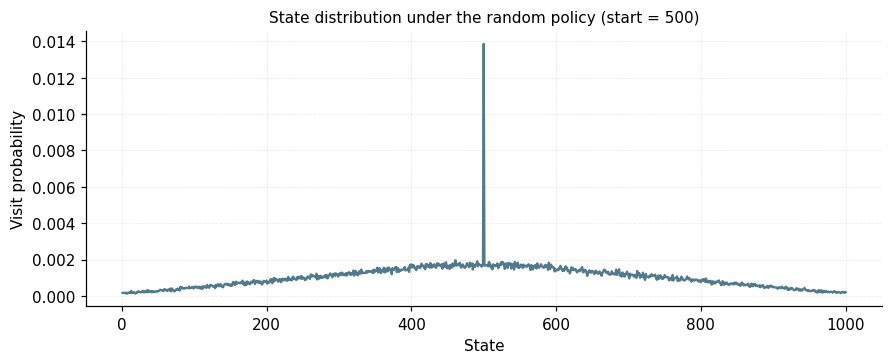

In [6]:
# Tabular vs state aggregation: how many independent parameters does each need?
tabular_params   = N_STATES                 # one value per non-terminal state
aggregation_K    = 10
print(f'tabular representation          : {tabular_params} independent parameters')
print(f'state aggregation ({aggregation_K} groups)     : {aggregation_K} parameters '
      f'({N_STATES // aggregation_K} states share each one)')

vf = ValueFunction(aggregation_K)
print('ValueFunction(10).params shape  :', vf.params.shape)

# Start-state-centric visits: in 2000 episodes only a narrow band of states is ever seen,
# so a tabular learner would leave most of the table untouched.
dist = np.zeros(N_STATES + 2)
for _ in range(2000):
    gradient_monte_carlo(ValueFunction(10), 0.0, dist)      # alpha = 0: pure statistics
dist /= dist.sum()
visited = (dist[1:-1] > 0).sum()
print(f'states visited at least once in 2000 episodes from state 500: {visited} / {N_STATES}')
plt.figure(figsize=(8, 3.2), constrained_layout=True)
plt.plot(STATES, dist[1:-1], color=ICONC)
plt.xlabel('State'); plt.ylabel('Visit probability')
plt.title('State distribution under the random policy (start = 500)', fontsize=10)
plt.show()


---
# Q2 — How does one parameter learn about many states?
> `ValueFunction` divides the 1,000 states into groups. Suppose there are **10 groups**.
> (1) How many states belong to each group? (2) Which parameter is used for state 137?
> (3) If the parameter associated with state 137 is changed, which other states are
> affected? (4) Why is this called generalization? *Infer the answers from the mapping
> implemented in the program.*


**Answer summary.** The mapping implemented in `ValueFunction.value/update` is
`group_index = (state - 1) // group_size` with `group_size = 1000 // 10 = 100`.

1. Each group holds **100** states.
2. For state 137: $(137-1)//100 = 1$, so state 137 is represented by parameter
   $\mathbf{w}_1$ (the **second** group, 0-indexed).
3. Changing $\mathbf{w}_1$ moves the estimate of **every state from 101 to 200** — all
   100 states whose index maps to group 1.
4. It is called *generalization* because experience gathered at one state is automatically
   applied to states that were never visited: the parameter is a **shared resource**, so
   the value function is no longer 1,000 independent memories but 10 shared ones. The
   flip side is **banding bias** — states inside a group are indistinguishable, so the
   approximation cannot resolve differences within the 100-state block.


In [7]:
num_of_groups = 10
vf = ValueFunction(num_of_groups)
group_size = vf.group_size
print(f'(1) group_size = 1000 // 10 = {group_size} states per group')

s = 137
g = (s - 1) // group_size
print(f'(2) group_index for state {s} = ({s}-1) // {group_size} = {g}  ->  parameter w[{g}] (2nd group)')

lo, hi = g * group_size + 1, (g + 1) * group_size
print(f'(3) changing w[{g}] affects every state in [{lo}, {hi}] = {hi-lo+1} states')

# (4) demonstrate generalization empirically: touch ONE state, watch 100 states move
vf.params[:] = 0.0
before = values_all_states_agg(vf).copy()
vf.update(0.5, s)                                   # a single update for state 137
after = values_all_states_agg(vf)
changed = np.where(after != before)[0] + 1
print(f'(4) after one update at state {s}: {len(changed)} states changed their value,')
print(f'    exactly the states {changed.min()}..{changed.max()}')


(1) group_size = 1000 // 10 = 100 states per group
(2) group_index for state 137 = (137-1) // 100 = 1  ->  parameter w[1] (2nd group)
(3) changing w[1] affects every state in [101, 200] = 100 states
(4) after one update at state 137: 100 states changed their value,
    exactly the states 101..200


---
# Q3 — What exactly is being learned by Gradient Monte Carlo?
> Consider an episode that starts at state 500 and eventually reaches the right terminal
> state. Explain why the program can use **the same final reward as the return for every
> visited state** in that episode. Your answer must consider $\gamma = 1$ and the fact
> that all non-terminal transitions have reward 0. Why would this no longer be true if
> intermediate transitions also produced non-zero rewards?


**Answer summary.** The return is defined as
$G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \dots$ up to termination. In this
environment every reward is 0 except the single terminal one, so if the episode ends at
time $T$ with $R_T$... more precisely with final payoff $R_T \in \{-1, +1\}$, then for
every $t < T$:

$$G_t \;=\; \underbrace{0 + \gamma\cdot 0 + \dots + \gamma^{T-t-1}\cdot 0}_{\text{all zero}}
\;+\; \gamma^{\,T-t-1}\, R_T.$$

With $\gamma = 1$ the discount factor is 1, so $G_t = R_T = +1$ **for every state visited
on the episode** — the whole trajectory shares one target. That is precisely why
`gradient_monte_carlo()` can compute `reward` once, in the interaction loop, and reuse the
same scalar inside the update loop (`delta = alpha * (reward - value)`). If intermediate
transitions had non-zero rewards, $G_t$ would become a *sum* of rewards weighted by
$\gamma^{k}$, different for each $t$ (earlier states see more future rewards; with
$\gamma \ne 1$ even the terminal payoff would be discounted differently per state), and
the program would have to accumulate per-time-step returns
$G_t = R_{t+1} + \gamma G_{t+1}$ backwards over the trajectory instead of reusing one
number.


In [8]:
np.random.seed(7)
state = START_STATE
trajectory, rewards = [state], []
while state not in END_STATES:
    state, r = step(state, get_action())
    trajectory.append(state); rewards.append(r)

T = len(rewards)
final_reward = rewards[-1]
print(f'episode: {T} steps, terminal state = {trajectory[-1]}, final reward = {final_reward:+d}')
print('first 10 states :', trajectory[:10], '...')
print('all intermediate rewards are zero?', all(r == 0 for r in rewards[:-1]))

# compute G_t backwards for every t (gamma = 1) and compare with the final reward
G, returns = 0.0, []
for r in reversed(rewards):
    G = r + 1.0 * G
    returns.append(G)
returns = list(reversed(returns))
print(f'return G_t for every visited state == final reward ?  '
      f'{all(g == final_reward for g in returns)}')
print('=> gradient_monte_carlo() may reuse the single scalar `reward` as the target for all states.')


episode: 64 steps, terminal state = 0, final reward = -1
first 10 states : [500, 474, 390, 483, 459, 502, 462, 511, 556, 500] ...
all intermediate rewards are zero? True
return G_t for every visited state == final reward ?  True
=> gradient_monte_carlo() may reuse the single scalar `reward` as the target for all states.


---
# Q4 — Calculate an actual parameter update
> A state has feature vector $\mathbf{x}(s) = [1,\ 0.5]$ and current approximation
> $\hat v(s,\mathbf{w}) = 0.4$. The observed Monte Carlo return is $G = 1$ and
> $\alpha = 0.1$. Using the gradient Monte Carlo update
> $\mathbf{w}_{new} = \mathbf{w} + \alpha\,[G - \hat v(s,\mathbf{w})]\,\nabla_\mathbf{w}\hat v(s,\mathbf{w})$,
> calculate the change in **both** parameters. Why do both parameters change even though
> the agent visited only one state?


**Answer — step-by-step calculation.** For a linear approximator
$\hat v(s,\mathbf{w}) = \mathbf{w}^\top\mathbf{x}(s)$, the gradient is the feature vector
itself: $\nabla_\mathbf{w}\hat v = \mathbf{x}(s) = [1, 0.5]$.

| Step | Symbol | Value |
|---|---|---|
| 1. Prediction | $\hat v(s,\mathbf{w})$ | $0.4$ |
| 2. Target | $G$ | $1$ |
| 3. Error | $G - \hat v$ | $1 - 0.4 = 0.6$ |
| 4. Scaled error (delta) | $\alpha\,(G-\hat v)$ | $0.1 \times 0.6 = 0.06$ |
| 5. Gradient | $\nabla_\mathbf{w}\hat v$ | $[1,\ 0.5]$ |
| 6. Parameter change | $\Delta\mathbf{w}$ | $0.06 \times [1, 0.5] = [0.06,\ 0.03]$ |
| 7. New weights | $\mathbf{w}_{new}$ | e.g. $[0.4,\ 0] + [0.06,\ 0.03] = [0.46,\ 0.03]$ |
| 8. New prediction | $\hat v(s,\mathbf{w}_{new})$ | $0.46 + 0.03 \times 0.5 = 0.475$ |

The prediction moved from 0.4 toward the target 1 by $0.06 \times \|\mathbf{x}\|^2 = 0.075$
— a partial step, exactly as stochastic approximation should.

**Why both parameters move.** The update touches the parameter vector, not "a state".
Both weights receive a share of the error proportional to their feature component:
weight 1 (coefficient of the constant feature) moves by $0.06$, weight 2 by
$0.06 \times 0.5 = 0.03$. This is generalization by construction — any other state whose
feature vector contains the same components is carried along by the same parameter
change, which is how one visit can improve predictions at many states.


In [9]:
x_s   = np.array([1.0, 0.5])          # feature vector of the visited state
G, alpha_true = 1.0, 0.1
w     = np.array([0.4, 0.0])          # any w with w.x = 0.4 reproduces V-hat = 0.4

v_hat      = w @ x_s                  # 1) prediction
error      = G - v_hat                # 2-3) target - prediction
delta      = alpha_true * error       # 4) scaled error
gradient   = x_s                      # 5) gradient of a linear form = x(s)
w_new      = w + delta * gradient     # 6-7) parameter update
v_hat_new  = w_new @ x_s              # 8) new prediction

print(f'prediction          V-hat(s,w)        = {v_hat:.3f}')
print(f'target              G                 = {G:.3f}')
print(f'error               G - V-hat         = {error:.3f}')
print(f'delta               alpha*(G - V-hat) = {delta:.3f}')
print(f'gradient            x(s)              = {gradient}')
print(f'parameter change    delta * x(s)      = {delta * gradient}')
print(f'new weights         w_new             = {w_new}')
print(f'new prediction      V-hat(s,w_new)    = {v_hat_new:.3f}   (moved {v_hat_new-v_hat:+.3f} toward 1)')


prediction          V-hat(s,w)        = 0.400
target              G                 = 1.000
error               G - V-hat         = 0.600
delta               alpha*(G - V-hat) = 0.060
gradient            x(s)              = [1.  0.5]
parameter change    delta * x(s)      = [0.06 0.03]
new weights         w_new             = [0.46 0.03]
new prediction      V-hat(s,w_new)    = 0.475   (moved +0.075 toward 1)


---
# Q5 — Why does the program use `gradient_monte_carlo()` instead of ordinary table updates?
> The program follows the sequence: *value prediction → reward − prediction → delta →
> `value_function.update(...)`*. Explain why **delta is not itself the change to the value
> function in every representation**. Compare what `update()` does for **state
> aggregation**, **tile coding**, and **polynomial/Fourier approximation**.


**Answer summary.** `delta = alpha * (target - prediction)` is the *temporal-difference
error scaled by the step size* — a single scalar. A tabular `V[s] += delta` works only
because a state's table entry **is** its parameter, i.e. the gradient is a one-hot vector.
With function approximation the scalar delta must be **converted into a parameter-space
direction by the gradient**, and each representation implements that conversion
differently inside its own `update()`:

| Representation | What `update(delta, s)` actually does | Parameters touched |
|---|---|---|
| State aggregation | `params[group(s)] += delta` — the whole delta goes to one weight | 1 (moves 100 state estimates) |
| Tile coding | `delta /= 50`, then every **active tile** in the 50 tilings gets `+= delta/50` | 50 (each by delta/50, so the value at `s` moves by exactly delta) |
| Poly/Fourier | `weights += delta * x(s)` — the delta is distributed proportionally to the feature values | `order+1` (all weights, weighted by their features) |

If `update()` had blindly added `delta` to every parameter (as a naive table loop would),
tile coding would move the prediction at $s$ by $50\times$ delta and the bases would move
it by $\sum_i x_i(s)\cdot$delta — both wrong by the norm of the feature vector. The
gradient factor $\nabla_\mathbf{w}\hat v$ in the update rule is exactly the bookkeeping
that keeps the *prediction* change equal to `delta` regardless of representation.


In [10]:
DELTA = 0.06          # one common scaled TD error for all three representations

# --- state aggregation: delta goes entirely to one group weight ---
vf_agg = ValueFunction(10)
vf_agg.params[:] = 0.0
vf_agg.update(DELTA, 137)
print('state aggregation : params after update      =', vf_agg.params)
print('                    value change at state 137 =', vf_agg.value(137), '(= delta, 100 states moved)')

# --- tile coding: delta/50 to each of the 50 active tiles ---
vf_tile = TilingsValueFunction(50, 200, 4)
before = vf_tile.params.copy()
vf_tile.update(DELTA, 137)
changed = np.argwhere(before != vf_tile.params)
print(f'tile coding       : {len(changed)} tiles updated by delta/50 = {DELTA/50:.5f} each')
print('                    value change at state 137 =', round(vf_tile.value(137), 6), '(still = delta)')

# --- polynomial bases: delta * x(s) added to the weight vector ---
vf_poly = BasesValueFunction(3, POLYNOMIAL_BASES)
s_norm = 137 / 1000
grad = np.asarray([f(s_norm) for f in vf_poly.bases])
vf_poly.weights[:] = 0.0
vf_poly.update(DELTA, 137)
print(f'polynomial basis  : gradient x(s) = {np.round(grad, 4)}')
print('                    weight change = delta * x(s) =', np.round(DELTA * grad, 6))
print(f'                    value change at state 137 = {vf_poly.value(137):.6f} (= delta * ||x||^2, NOT delta)')


state aggregation : params after update      = [0.   0.06 0.   0.   0.   0.   0.   0.   0.   0.  ]
                    value change at state 137 = 0.06 (= delta, 100 states moved)
tile coding       : 50 tiles updated by delta/50 = 0.00120 each
                    value change at state 137 = 0.06 (still = delta)
polynomial basis  : gradient x(s) = [1.     0.137  0.0188 0.0026]
                    weight change = delta * x(s) = [0.06     0.00822  0.001126 0.000154]
                    value change at state 137 = 0.061148 (= delta * ||x||^2, NOT delta)


---
# Q6 — What is the role of $\nabla_\mathbf{w}\hat v$?
> The program uses the general update $\mathbf{w} \leftarrow \mathbf{w} + \alpha\,e\,
> \nabla_\mathbf{w}\hat v$ (with $e$ the scaled error). Explain why the **same learning
> rule** can work with three different representations. Determine what
> $\nabla_\mathbf{w}\hat v$ effectively is for (1) state aggregation, (2) tile coding,
> (3) polynomial/Fourier bases. Why is the gradient different even though the learning
> rule has the same overall form?


**Answer summary.** The learning rule is *representation-agnostic* because the
representation-specific knowledge is packed into the gradient vector
$\nabla_\mathbf{w}\hat v(s,\mathbf{w})$ — it answers "if parameter $w_i$ changes by one
unit, how much does the estimate at $s$ change?" For a **linear** approximator
$\hat v = \mathbf{w}^\top\mathbf{x}(s)$ the gradient is simply $\mathbf{x}(s)$:

1. **State aggregation:** $\mathbf{x}(s)$ is a one-hot vector (1 for the state's group, 0
   elsewhere) → the gradient "selects" one parameter.
2. **Tile coding:** $\mathbf{x}(s)$ has 1 in the 50 active tiles (or $1/50$ each after the
   program divides delta equally — an equivalent re-scaling) → the gradient selects the
   **shared** feature set of nearby states.
3. **Polynomial:** $\mathbf{x}(s) = [1, s, s^2, \dots]$; **Fourier:**
   $\mathbf{x}(s) = [1, \cos\pi s, \cos 2\pi s, \dots]$ with $s\in[0,1]$ → the gradient is a
   dense vector; every parameter participates, each weighted by its basis value.

The gradient differs because it is the **derivative of the chosen parameterisation** —
different $\hat v$ means different sensitivity of the output to each weight. The rule
$\mathbf{w} \mathrel{+}= \alpha\, e\, \nabla\hat v$ stays valid because it is just
stochastic gradient descent on the squared error
$\big(G - \hat v(s,\mathbf{w})\big)^2$, whatever smooth form $\hat v$ has.


In [11]:
s = 137
# (1) state aggregation gradient: one-hot on the state's group
g_agg = np.zeros(10)
g_agg[(s - 1) // 100] = 1.0
print('(1) aggregation gradient (10 params):', g_agg.astype(int), ' -> one-hot selector')

# (2) tile coding gradient: 1/50 on each active tile
vt = TilingsValueFunction(50, 200, 4)
g_tile = np.zeros_like(vt.params)
for t in range(vt.numOfTilings):
    g_tile[t, (s - vt.tilings[t]) // vt.tileWidth] = 1.0 / vt.numOfTilings
print('(2) tile coding gradient:', g_tile.shape, f'-> {vt.numOfTilings} entries of 1/50 = {1/50:.3f}')

# (3) polynomial and Fourier gradients (order 2) at s/1000
x = s / 1000.0
g_poly  = np.array([x**i for i in range(3)])
g_four  = np.array([np.cos(i * np.pi * x) for i in range(3)])
print(f'(3) s/1000 = {x:.3f}')
print('    polynomial gradient [1, s, s^2]      =', np.round(g_poly, 4))
print('    fourier gradient   [1, cos, cos 2pi] =', np.round(g_four, 4))
print()
print('same rule w += alpha*e*grad_v works for all: the gradient encodes the representation.')


(1) aggregation gradient (10 params): [0 1 0 0 0 0 0 0 0 0]  -> one-hot selector
(2) tile coding gradient: (50, 6) -> 50 entries of 1/50 = 0.020
(3) s/1000 = 0.137
    polynomial gradient [1, s, s^2]      = [1.     0.137  0.0188]
    fourier gradient   [1, cos, cos 2pi] = [1.     0.9088 0.6518]

same rule w += alpha*e*grad_v works for all: the gradient encodes the representation.


---
# Q7 — Why is the TD algorithm called **semi-gradient**?
> Study `semi_gradient_temporal_difference()` and determine the target used when $n=1$.
> Compare it with the Monte Carlo target. Which part of the TD target depends on the
> current parameters $\mathbf{w}$, and why does the algorithm nevertheless use the
> gradient only with respect to the current prediction?


**Answer summary.** For $n = 1$ the update target is the one-step bootstrapped return

$$\underbrace{G_t}_{\text{MC target}:\ \text{independent of }\mathbf{w}}
\qquad\text{vs.}\qquad
\underbrace{R_{t+1} + \gamma\,\hat v(S_{t+1}, \mathbf{w})}_{\text{TD target}:\ \text{depends on }\mathbf{w}}.$$

The bootstrap term $\hat v(S_{t+1}, \mathbf{w})$ is itself a *guess computed from the
weights we are updating*. A full gradient treatment would differentiate through it too
(that is the gradient of the residual $(R_{t+1} + \gamma\hat v(S_{t+1}) - \hat v(S_t))^2$
w.r.t. both occurrences of $\mathbf{w}$). The program — like standard semi-gradient TD —
**treats the target as a constant**: it uses
$\nabla_\mathbf{w}\hat v(S_t, \mathbf{w})$ only, i.e. the gradient of the *current
prediction at the state being updated*. Hence **semi**-gradient. The benefits: the update
is simpler and cheaper, avoids the instability of pushing gradient through a moving
target, and by Chapter 9's argument it still converges (in expectation) to the
$\mathbf{w}^*$ of the projected Bellman equation for linear function approximation. The
price is bias: the target inherits the errors of the current value function.


In [12]:
np.random.seed(11)
vf = ValueFunction(10)
# give the approximator some non-trivial values (a linear ramp) to make bootstrapping visible
vf.params[:] = np.linspace(-0.8, 0.8, 10)

# take ONE transition from the start state
state = START_STATE
action = get_action()
next_state, reward = step(state, action)

# --- n = 1 target: R1 + gamma * V-hat(S2, w) ---
td_target = reward + 1.0 * vf.value(next_state)
print(f'transition: S1 = {state}, A = {action:+d}, R1 = {reward}, S2 = {next_state}')
print(f'bootstrap value  V-hat(S2, w) = {vf.value(next_state):+.4f}  (depends on w!)')
print(f'TD(0) target     R1 + gamma*V-hat(S2,w) = {td_target:+.4f}')
print(f'MC target        G_t (final episode reward, w-independent) = +1 (if the episode ends right)')

# --- prove the TD target moves when w moves, the MC target does not ---
g2 = (next_state - 1) // vf.group_size
vf.params[g2] += 0.5
print(f'\nafter changing parameter w[{g2}] by +0.5:')
print(f'  V-hat(S2, w) : {vf.value(next_state):+.4f}   -> TD target moved to {reward + vf.value(next_state):+.4f}')
print(f'  MC target    : still +1 (G_t is data, not a function of w)')
print('\n=> the algorithm differentiates only V-hat(S_t, w) (the prediction), not the target.')
print('   That is exactly what "semi-gradient" means.')


transition: S1 = 500, A = -1, R1 = 0, S2 = 419
bootstrap value  V-hat(S2, w) = -0.0889  (depends on w!)
TD(0) target     R1 + gamma*V-hat(S2,w) = -0.0889
MC target        G_t (final episode reward, w-independent) = +1 (if the episode ends right)

after changing parameter w[4] by +0.5:
  V-hat(S2, w) : +0.4111   -> TD target moved to +0.4111
  MC target    : still +1 (G_t is data, not a function of w)

=> the algorithm differentiates only V-hat(S_t, w) (the prediction), not the target.
   That is exactly what "semi-gradient" means.


---
# Q8 — What happens when *n* changes?
> The program tests $n = 1, 2, 4, 8, \dots$ (powers of two). Explain what happens to the
> TD target as $n$ increases. Is increasing $n$ making the algorithm **more like Monte
> Carlo**, or **more like one-step TD**? Why?


**Answer summary.** The n-step target mixes $n$ real rewards with one bootstrap:

$$G_{t:t+n} = R_{t+1} + \gamma R_{t+2} + \dots + \gamma^{n-1}R_{t+n} + \gamma^{n}\hat v(S_{t+n},\mathbf{w}).$$

- **As $n$ grows**, fewer bootstrapped values and more *actual observed rewards* enter the
  target; at $n \ge T - t$ the bootstrap disappears entirely and $G_{t:t+n}$ **is** the
  Monte Carlo return $G_t$. So increasing $n$ makes the method **more like Monte Carlo**:
  less bias (the target no longer inherits the errors of $\hat v$) but **more variance**
  (the target now depends on a longer, more random reward sequence).
- **As $n \to 1$**, the target is mostly bootstrap: low variance, but biased towards
  whatever the current weights already believe.

The experiment below (scaled reproduction of Figure 9.2 right) shows the practical
consequence: intermediate $n$ (here $n = 8\text{–}16$) achieves the lowest RMS error —
one-step TD learns fast but plateaus higher, large $n$ approaches MC's variance and needs
smaller $\alpha$. Each curve also shifts the **largest usable learning rate** downwards as
$n$ grows, because $n$ real rewards make the target magnitude (and hence the update
noise) larger.


  run 1/10 finished (0.2s)


  run 2/10 finished (0.5s)


  run 3/10 finished (0.7s)


  run 4/10 finished (0.9s)


  run 5/10 finished (1.2s)
  run 6/10 finished (1.4s)


  run 7/10 finished (1.6s)


  run 8/10 finished (1.9s)
  run 9/10 finished (2.1s)


  run 10/10 finished (2.3s)
done


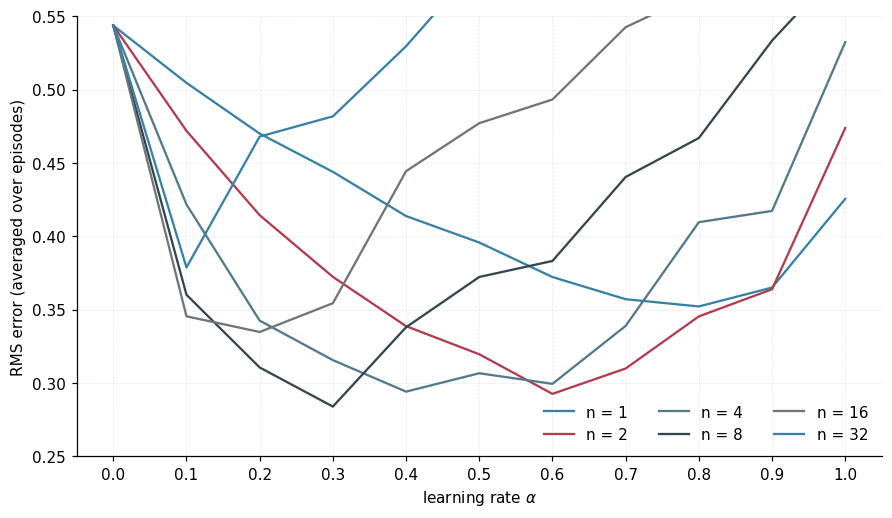

best (n, alpha) combination: n = 8, alpha = 0.3, RMS = 0.284


In [13]:
# scaled reproduction of Figure 9.2 (right): RMS error vs alpha for several n
steps    = [1, 2, 4, 8, 16, 32]          # original: 2**0 .. 2**9
alphas   = np.arange(0, 1.1, 0.1)        # 11 learning rates, including 0
episodes, runs = 10, 10                  # original: 10 episodes, 100 runs

errors = np.zeros((len(steps), len(alphas)))
t0 = time.time()
for run in range(runs):
    for si, n in enumerate(steps):
        for ai, alpha in enumerate(alphas):
            vf = ValueFunction(20)                     # 20 groups, as in the original
            for ep in range(episodes):
                semi_gradient_temporal_difference(vf, n, alpha)
                sv = values_all_states_agg(vf)         # vectorised RMS evaluation
                errors[si, ai] += np.sqrt(np.sum((sv - true_value[1:-1])**2) / N_STATES)
    print(f'  run {run+1}/{runs} finished ({time.time()-t0:.1f}s)')
errors /= episodes * runs
print('done')

fig, ax = plt.subplots(figsize=(8, 4.6), constrained_layout=True)
for si, n in enumerate(steps):
    ax.plot(alphas, errors[si], label=f'n = {n}')
ax.set_xlabel(r'learning rate $\alpha$'); ax.set_ylabel('RMS error (averaged over episodes)')
ax.set_ylim(0.25, 0.55); ax.set_xticks(alphas)
ax.legend(ncol=3, loc='lower right')
fig.savefig(f'{FIG_DIR}/fig_q8_nstep_rms.png')
plt.show()
best = np.unravel_index(np.nanargmin(np.where(errors > 0, errors, np.inf)), errors.shape)
print(f'best (n, alpha) combination: n = {steps[best[0]]}, alpha = {alphas[best[1]]:.1f}, '
      f'RMS = {errors[best]:.3f}')


---
# Q9 — Why is the "true value" calculated **before** learning?
> `true_value = compute_true_value()` runs before the experiments. Explain (1) how the
> reference is obtained, (2) why it is useful even though the learning algorithms
> themselves estimate the value function, (3) why the program needs it for the RMS error
> plots.


**Answer summary.**
1. **How it is obtained.** `compute_true_value()` does *model-based iterative policy
   evaluation* (a form of asynchronous value iteration): starting from the linear guess
   $v_0(s) \propto s$, it sweeps over all 1000 states and replaces each value by the exact
   Bellman expectation of the random policy,
   $V(s) \leftarrow \frac{1}{200}\sum_{a,u} V(\mathrm{clip}(s+au))$, until
   $\sum_s |\Delta V(s)| < 10^{-2}$. Because the transition model (uniform stride, fair
   coin) is *known*, this is plain dynamic programming — no sampling, no learning.
2. **Why useful.** The learning algorithms are *model-free* — they only see sampled
   episodes, and their output depends on sample noise, step size and representation
   capacity. The DP solution is the exact yardstick that says what they are *trying* to
   approximate. Without it we could only compare algorithms against each other, never
   against the truth.
3. **Why needed for RMS plots.** Every figure in this lab (9.1, 9.2, 9.5, 9.10) measures
   $\mathrm{RMS} = \sqrt{\frac{1}{1000}\sum_{s=1}^{1000}\big(\hat v(s,\mathbf{w}) -
   v_\pi(s)\big)^2}$. That formula requires $v_\pi(s)$ for **all** states — including the
   ones the agent almost never visits (see the Q1 distribution plot). Sampled returns can
   never provide those; only the DP reference can. The cell below visualises the sweep-by-
   sweep convergence of the DP reference.


DP reference converged after 85 synchronous sweeps (stopping rule: sum |dV| < 1e-2)


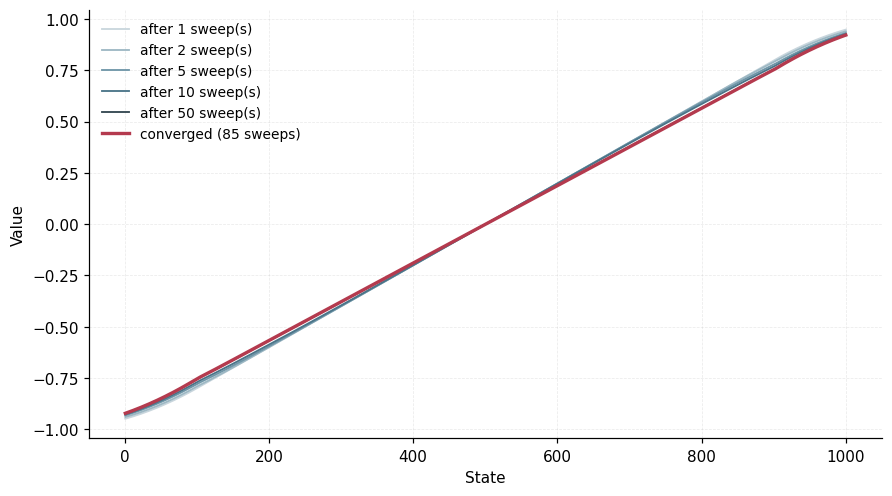

the initial linear guess is already good (the environment is symmetric and linear in
expectation), but only the DP sweeps sharpen it into the exact v_pi used for RMS plots.


In [14]:
def compute_true_value_trace(snapshots=(1, 2, 5, 10, 50)):
    '''Same DP as compute_true_value(), but records intermediate sweeps for plotting.'''
    v = np.arange(-1001, 1003, 2) / 1001.0
    idx = np.empty((2 * STEP_RANGE, N_STATES + 2), dtype=int)
    k = 0
    for action in ACTIONS:
        for stride in range(1, STEP_RANGE + 1):
            idx[k] = np.clip(np.arange(N_STATES + 2) + stride * action, 0, N_STATES + 1)
            k += 1
    idx = idx[:, STATES]
    trace, sweeps = {}, 0
    while True:
        old = v.copy()
        v[STATES] = v[idx].mean(axis=0)
        sweeps += 1
        if sweeps in snapshots:
            trace[sweeps] = v.copy()
        if np.abs(old - v).sum() < 1e-2:
            break
    v[0] = v[-1] = 0.0
    return v, trace, sweeps

v_final, trace, sweeps = compute_true_value_trace()
print(f'DP reference converged after {sweeps} synchronous sweeps (stopping rule: sum |dV| < 1e-2)')

fig, ax = plt.subplots(figsize=(8, 4.4), constrained_layout=True)
cmap_colors = ['#c9d6dd', '#9db8c4', '#6f96a8', '#4a7488', '#334650']
for (k, (n_sweep, v_snap)) in zip(cmap_colors, trace.items()):
    ax.plot(STATES, v_snap[1:-1], color=k, lw=1.2, label=f'after {n_sweep} sweep(s)')
ax.plot(STATES, v_final[1:-1], color=ACCENT2, lw=2.2, label=f'converged ({sweeps} sweeps)')
ax.set_xlabel('State'); ax.set_ylabel('Value')
ax.legend(loc='upper left', fontsize=9)
fig.savefig(f'{FIG_DIR}/fig_q9_true_value_convergence.png')
plt.show()
print('the initial linear guess is already good (the environment is symmetric and linear in')
print('expectation), but only the DP sweeps sharpen it into the exact v_pi used for RMS plots.')


---
# Q10 — Why does state aggregation produce a **piecewise-constant** approximation?
> Sketch the approximate value function for 10 groups. Why does the graph have abrupt
> jumps between groups instead of a smooth curve? Would **increasing the number of
> groups** necessarily make the learned function better?


**Answer summary.** With 10 groups, $\hat v(s) = w_{(s-1)//100}$: the estimate is one
constant per 100-state block, so the learned "curve" is a **staircase** with 10 steps
(see the experiment below — this is the required sketch). Jumps occur at group boundaries
because the *same* weight applies on both sides of the boundary only up to state 100;
state 100 reads $w_0$, state 101 reads $w_1$, and nothing in the representation enforces
continuity — the weights are updated independently by whichever returns happen to hit
each group.

**More groups = better?** Not necessarily — this is the distinction between
**representation capacity** and **learning quality**:
- More groups ⇒ smaller bias (finer resolution of the true curve), but each group receives
  **proportionally fewer updates**, so the variance of each weight estimate grows; with a
  fixed budget of episodes a fine partition can be *noisier* than a coarse one.
- In the limit of 1000 groups we recover the tabular method with no generalization at all
  (Q1) — the worst option here.
- The best choice balances bias against variance given the sample budget; in the
  original Figure 9.2 the book uses 10–20 groups for exactly this reason. The run below
  also plots the **state distribution**: learning effort concentrates where the agent
  actually goes, and aggregation spreads it over whole blocks.


  episode   5000/20000  (1.5s)


  episode  10000/20000  (2.7s)


  episode  15000/20000  (4.0s)


  episode  20000/20000  (5.3s)
final RMS error vs DP reference: 0.0569


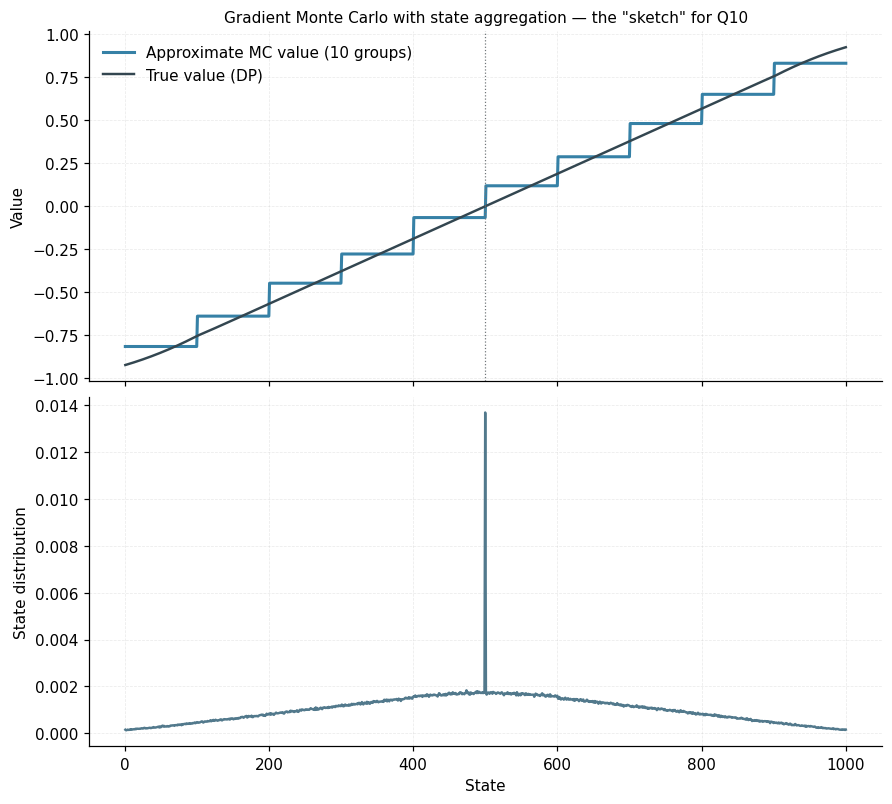

observed: piecewise-constant steps of 100 states; visible jumps at group boundaries;
flat where visits are rare, best resolved around the start state.


In [15]:
# scaled reproduction of Figure 9.1: gradient MC with 10-group state aggregation
episodes, alpha = 20000, 1e-4        # original: 1e5 episodes, alpha = 2e-5 (same alpha*episodes budget)
vf = ValueFunction(10)
distribution = np.zeros(N_STATES + 2)
t0 = time.time()
for ep in range(episodes):
    gradient_monte_carlo(vf, alpha, distribution)
    if (ep + 1) % 5000 == 0:
        print(f'  episode {ep+1:>6}/{episodes}  ({time.time()-t0:.1f}s)')
distribution /= distribution.sum()
sv = values_all_states_agg(vf)
rms = np.sqrt(np.mean((sv - true_value[1:-1])**2))
print(f'final RMS error vs DP reference: {rms:.4f}')

fig, axes = plt.subplots(2, 1, figsize=(8, 7.2), constrained_layout=True, sharex=True)
axes[0].plot(STATES, sv, color=ACCENT, lw=2.0, label='Approximate MC value (10 groups)')
axes[0].plot(STATES, true_value[1:-1], color=DARKC, lw=1.6, label='True value (DP)')
axes[0].axvline(500, color=MUTED, lw=0.8, ls=':')
axes[0].set_ylabel('Value')
axes[0].legend(loc='upper left')
axes[0].set_title('Gradient Monte Carlo with state aggregation — the "sketch" for Q10', fontsize=10)
axes[1].plot(STATES, distribution[1:-1], color=ICONC, lw=1.6)
axes[1].set_xlabel('State'); axes[1].set_ylabel('State distribution')
fig.savefig(f'{FIG_DIR}/fig_q10_state_aggregation.png')
plt.show()
print('observed: piecewise-constant steps of 100 states; visible jumps at group boundaries;')
print('flat where visits are rare, best resolved around the start state.')


---
# Q11 — Why can tile coding generalize **more smoothly** than state aggregation?
> Tile coding uses multiple tilings, overlapping tiles, and several active parameters per
> state. Explain why a small change in state can still **share parameters** with the
> previous state. Compare state aggregation with tile coding: which representation
> produces smoother changes in $\hat v(s)$, and why?


**Answer summary.** In `TilingsValueFunction(50, 200, 4)` the 50 tilings are shifted
from each other by **4 states**. A state activates exactly one tile *per tiling*, i.e. 50
weights, and its estimate is the **sum** of those 50 weights. Move the state by one step:
in most tilings the *same* tile is still active — only the tiling(s) whose boundary falls
between the two states change (each boundary line is only 4 states away from its
neighbour, so per single-state move at most a few of the 50 tiles switch). Hence
$\hat v$ changes by a **small fraction** ($\sim\frac{1}{50}$ of a tile-weight difference)
instead of jumping wholesale.

| Property | State aggregation (1 tiling) | Tile coding (50 tilings, offset 4) |
|---|---|---|
| Active parameters per state | 1 | 50 |
| Effective resolution | 100-state blocks | 4-state steps (offset granularity) |
| $\hat v$ at neighbouring states | identical inside a block | differs only where a boundary is crossed |
| Smoothness of $\hat v(s)$ | staircase with 100-wide steps | fine staircase (amplitude 1/50 per tile switch) |
| Parameters in this configuration | 10 | 50 × 6 = 300 |

**Which is smoother?** Tile coding, decisively. Coarse coding intuition: overlapping,
offset receptive fields turn discrete parameter sharing into a fine-grained, graded
generalization kernel; state aggregation is the degenerate case of coarse coding with a
single, non-overlapping tiling. The experiment below reproduces Figure 9.10 (original
5,000-episode budget, same gradient-MC algorithm and decaying $\alpha = 1/(ep+1)$ for
both): the aggregation curve **plateaus around 0.15–0.20 RMS** — its 5-group
representation floor plus the residual estimation noise that the shrinking step size can
no longer remove — while tile coding keeps descending towards a much lower level
(\~0.05–0.07), several times better. The asymptote, not the speed of the first few
hundred episodes, is the honest measure of representation quality here.


  Tile coding (50 tilings): done (15.1s), final RMS = 0.0663


  State aggregation (one tiling, 5 groups): done (16.4s), final RMS = 0.2016


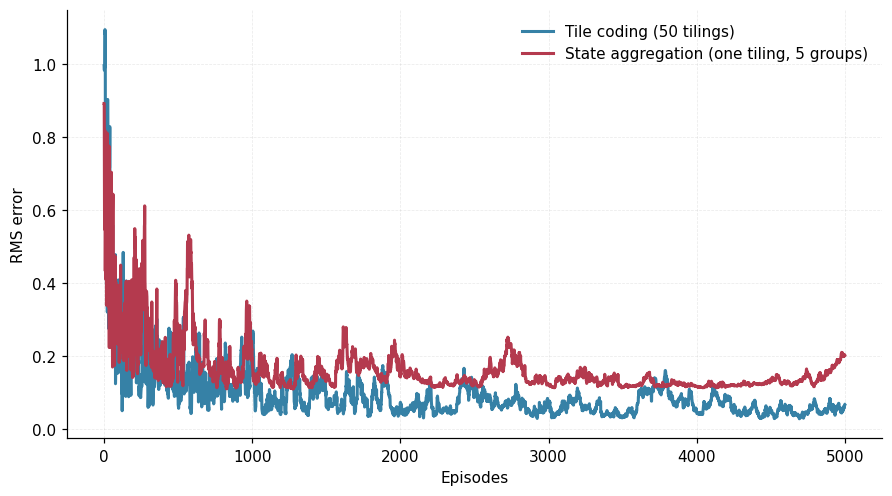

tile coding generalizes over 4-state offsets -> many more useful updates per episode,
and 300 parameters resolve the value curve far better than 5 block parameters.


In [16]:
# reproduction of Figure 9.10: tile coding vs one-tiling state aggregation (original budget)
episodes = 5000                         # original: 5000 (alpha = 1/(ep+1) decaying in both)
num_of_tilings, tile_width, tiling_offset = 50, 200, 4
labels = ['Tile coding (50 tilings)', 'State aggregation (one tiling, 5 groups)']
vfs = [TilingsValueFunction(num_of_tilings, tile_width, tiling_offset),
       ValueFunction(N_STATES // tile_width)]
errors = np.zeros((2, episodes))
t0 = time.time()
for i, vf in enumerate(vfs):
    for ep in range(episodes):
        alpha = 1.0 / (ep + 1)                       # decaying step size, as in the original
        gradient_monte_carlo(vf, alpha)
        sv = values_all_states_tiling(vf) if i == 0 else values_all_states_agg(vf)
        errors[i, ep] = np.sqrt(np.mean((true_value[1:-1] - sv)**2))
    print(f'  {labels[i]}: done ({time.time()-t0:.1f}s), final RMS = {errors[i, -1]:.4f}')

fig, ax = plt.subplots(figsize=(8, 4.4), constrained_layout=True)
ax.plot(errors[0], color=ACCENT,  lw=2.0, label=labels[0])
ax.plot(errors[1], color=ACCENT2, lw=2.0, label=labels[1])
ax.set_xlabel('Episodes'); ax.set_ylabel('RMS error')
ax.legend(loc='upper right')
fig.savefig(f'{FIG_DIR}/fig_q11_tile_coding.png')
plt.show()
print('tile coding generalizes over 4-state offsets -> many more useful updates per episode,')
print('and 300 parameters resolve the value curve far better than 5 block parameters.')


---
# Q12 — Why can two representations have different learning curves **with the same RL algorithm**?
> Two agents run exactly the same Gradient Monte Carlo, same environment, same episodes,
> same rewards — one with polynomial features, one with Fourier features. Why can they
> still produce different approximation errors? (Discuss representation, basis functions,
> generalization, parameter sharing, approximation capacity, learning-rate sensitivity.)
> Is the learning algorithm alone sufficient to determine performance?


**Answer summary.** The algorithm supplies only *targets* and *update timing*; the
**geometry of the parameter space** is set by the features, and that geometry controls
everything the update does:

- **Basis functions / capacity.** After normalising $s \in [0,1]$, the polynomial features
  $1, s, s^2, \dots, s^{20}$ are *highly correlated* (nearly collinear — all monotone,
  almost flat at the low end), so the span of low-order polynomials cannot reproduce the
  S-shaped, odd-symmetric true value well, and high orders add capacity mostly where there
  is no data. Fourier features $\cos(0), \cos(\pi s), \cos(2\pi s), \dots$ are **orthogonal
  on $[0,1]$** — a much better-conditioned basis that represents smooth symmetric
  components efficiently, and odd-symmetry about 0.5 is expressible with few terms.
- **Parameter sharing / generalization.** Polynomial weight $w_i$ scales the global trend
  $s^i$; a single update near $s=1$ (where $s^i$ is large) shifts estimates far away
  (where $s^i \approx 0$ barely notices) — an unbalanced, state-dependent step. Fourier
  features distribute the correction over a *spatially spread* cosine lobe, giving more
  even generalization across the state space.
- **Learning-rate sensitivity.** The effective step at state $s$ is
  $\alpha\, e\, \|\mathbf{x}(s)\|^2$. For polynomials this norm varies wildly with $s$ and
  explodes with order (values up to $\sim\!21$ features near $s=1$), so one $\alpha$ cannot
  fit all states — the program needs the tiny $10^{-4}$, and convergence is slow. Fourier
  features have $\|\mathbf{x}\|^2$ bounded ($\approx$ order/2 on average) and
  orthogonalised directions, so the same tiny $\alpha$ makes steadier progress.

**Therefore: no — the algorithm alone is not sufficient.** Performance is a property of
the *(algorithm × representation)* pair. The experiment below (scaled Figure 9.5) shows
Fourier dominating polynomial at every order, and higher order hurting polynomial more.


  order  5: done (8.7s)  poly RMS = 0.192, fourier RMS = 0.081


  order 10: done (20.2s)  poly RMS = 0.144, fourier RMS = 0.069


  order 20: done (37.9s)  poly RMS = 0.206, fourier RMS = 0.051


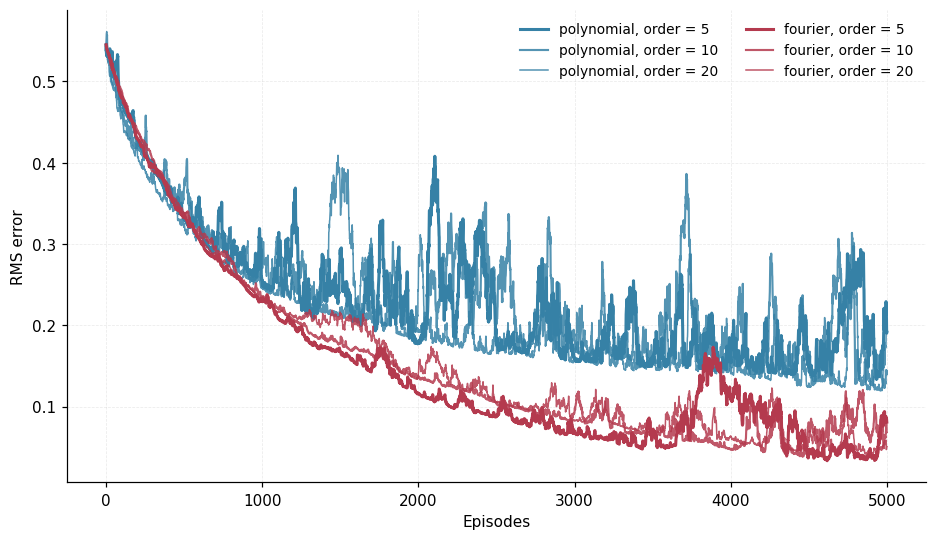

same algorithm, same episodes, same rewards -> still very different curves, because
the features define the geometry (conditioning, capacity, generalization) of learning.


In [17]:
# reproduction of Figure 9.5: polynomial vs Fourier bases, gradient MC (original budget)
runs, episodes = 1, 5000                # original: 5000 episodes
orders = [5, 10, 20]
alphas = [1e-4, 5e-5]                   # [polynomial alpha, fourier alpha] - as in the original
kind_labels = ['polynomial', 'fourier']
errors = np.zeros((2, len(orders), episodes))
t0 = time.time()
for oi, order in enumerate(orders):
    vfs = [BasesValueFunction(order, POLYNOMIAL_BASES),
           BasesValueFunction(order, FOURIER_BASES)]
    mats = [basis_matrix(vfs[0]), basis_matrix(vfs[1])]   # precomputed features (1000 x (order+1))
    for j, vf in enumerate(vfs):
        F = mats[j]
        for ep in range(episodes):
            gradient_monte_carlo(vf, alphas[j])
            sv = F @ vf.weights                            # vectorised evaluation
            errors[j, oi, ep] = np.sqrt(np.mean((true_value[1:-1] - sv)**2))
    print(f'  order {order:>2}: done ({time.time()-t0:.1f}s)  '
          f'poly RMS = {errors[0, oi, -1]:.3f}, fourier RMS = {errors[1, oi, -1]:.3f}')

fig, ax = plt.subplots(figsize=(8.4, 4.8), constrained_layout=True)
styles = [('-', 2.0), ('-', 1.4), ('-', 1.0)]
for j, kind in enumerate(kind_labels):
    for oi, order in enumerate(orders):
        ls, lw = styles[oi]
        ax.plot(errors[j, oi], linestyle=ls, lw=lw,
                color=ACCENT if j == 0 else ACCENT2,
                alpha=1.0 if oi == 0 else 0.85,
                label=f'{kind}, order = {order}')
ax.set_xlabel('Episodes'); ax.set_ylabel('RMS error')
ax.legend(ncol=2, fontsize=9, loc='upper right')
fig.savefig(f'{FIG_DIR}/fig_q12_bases.png')
plt.show()
print('same algorithm, same episodes, same rewards -> still very different curves, because')
print('the features define the geometry (conditioning, capacity, generalization) of learning.')


---
# Q13 — Optional challenge: separate the **three sources of learning behaviour**
> Identify which component is responsible for (a) the learning target, (b) the parameter
> update, (c) generalization across states — choosing from: *Gradient MC / TD*, *learning
> rate α*, *value-function representation*. Then explain why changing **only the
> representation** can change the final approximation even when the RL algorithm is
> unchanged.


**Answer summary.**

| Behaviour | Responsible component | Where in the code |
|---|---|---|
| (a) **Learning target** | the algorithm: Gradient MC (episode return $G$) vs semi-gradient n-step TD ($n$ rewards + bootstrap) | `gradient_monte_carlo()` reuses the terminal `reward`; `semi_gradient_temporal_difference()` sums `rewards[...]` and adds `value(states[update_time+n])` |
| (b) **Parameter update** | the update rule and the step size $\alpha$ (scales the error; also controls stability/speed, e.g. the decaying $1/(ep+1)$ in Q11) | `delta = alpha * (target - prediction)` and each `update(delta, state)` |
| (c) **Generalization across states** | the value-function representation (which parameters a state activates) | `ValueFunction` (one-hot group), `TilingsValueFunction` (50 overlapping tiles), `BasesValueFunction` (dense features) |

**Why representation alone changes the outcome.** Given the same targets and the same
$\alpha$, the *direction and spread* of every update in parameter space is
$\nabla_\mathbf{w}\hat v = \mathbf{x}(s)$ (Q6). Changing the representation changes
$\mathbf{x}(s)$, hence (i) which and how many parameters move, (ii) how the correction is
distributed over the state space (generalization kernel), (iii) the conditioning of the
optimisation (Q12), and (iv) the best achievable approximation error for a given number
of parameters (capacity / bias). The target can be perfect and the step size ideal, yet a
representation that cannot *express* the value function — or expresses it with ill-
conditioned features — will converge slowly or to a poor approximation. Learning
behaviour is the joint product **target × step size × representation**; this lab's three
experiments (Q8: target, Q10/Q11: representation sharpness, Q12: representation
conditioning) isolate exactly these factors.


In [18]:
# map the three sources onto the actual code objects
mapping = [
    ('Learning target',        'Algorithm (MC vs TD)',   'gradient_monte_carlo(): terminal reward as G  |  '
                                                 'semi_gradient_temporal_difference(): n rewards + bootstrap'),
    ('Parameter update size',  'alpha + delta rule',     'delta = alpha * (target - prediction); update() applies it'),
    ('Generalization',         'Representation',         'ValueFunction / TilingsValueFunction / BasesValueFunction'),
]
print(f'{"Source of behaviour":<24} | {"Component":<22} | Code evidence')
print('-' * 118)
for a, b, c in mapping:
    print(f'{a:<24} | {b:<22} | {c}')
print()
print('Q8 experiment varied the target      (n)  -> different RMS curves with the SAME representation.')
print('Q10/Q11 varied the representation         -> different sharpness with the SAME MC algorithm.')
print('Q12 varied only the features              -> different curves with the SAME algorithm AND alpha.')
print('=> all three components jointly determine learning behaviour.')


Source of behaviour      | Component              | Code evidence
----------------------------------------------------------------------------------------------------------------------
Learning target          | Algorithm (MC vs TD)   | gradient_monte_carlo(): terminal reward as G  |  semi_gradient_temporal_difference(): n rewards + bootstrap
Parameter update size    | alpha + delta rule     | delta = alpha * (target - prediction); update() applies it
Generalization           | Representation         | ValueFunction / TilingsValueFunction / BasesValueFunction

Q8 experiment varied the target      (n)  -> different RMS curves with the SAME representation.
Q10/Q11 varied the representation         -> different sharpness with the SAME MC algorithm.
Q12 varied only the features              -> different curves with the SAME algorithm AND alpha.
=> all three components jointly determine learning behaviour.


---
## Conclusion

- **Function approximation** turns 1,000 independent memories into $d \ll 1000$ shared
  parameters, buying generalization at the price of bias (Q1, Q2).
- With $\gamma=1$ and a single terminal payoff, **one reward is the whole return** — the
  core simplification gradient MC exploits (Q3), while the numeric update shows how one
  visit moves *several* parameters along the feature direction (Q4).
- `delta` is a scalar in prediction space; the **gradient** translates it into parameter
  space, differently for each representation (Q5, Q6).
- **Semi-gradient TD** bootstraps from its own estimate and deliberately skips the
  gradient through the target (Q7); growing $n$ interpolates smoothly towards Monte
  Carlo, with intermediate $n$ optimal here (Q8).
- The DP-computed **reference value function** is what makes RMS measurement possible at
  all (Q9).
- **Representation determines the quality ceiling and the speed of learning**: state
  aggregation gives the staircase of Q10, tile coding's overlapping tilings give smooth,
  fine-grained generalization (Q11), and Fourier features condition the same algorithm
  far better than polynomials (Q12). Targets, step sizes and representations are the
  three separable levers of learning behaviour (Q13).

### References
1. R. S. Sutton & A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed., MIT
   Press, 2018 — Chapter 9 (Sections 9.1–9.5), Figures 9.1, 9.2, 9.5, 9.10.
2. S. Zhang's reference implementation of the Chapter 9 figures (`random_walk.py`,
   2016–2018), used as the starting point for this notebook.
